# Single-location state and measurement optimization

$M=1$, $K\in\{3,4,5\}$, $N\in\{2,4,6,8,10\}$, with 30 instances per field family and $K$. Budgets share the same field instances. Field priors are uniform.

The state is $|\psi\rangle=\sum_{w=0}^N\sqrt{p_w}|D_N^w\rangle$. Product, GHZ and equal-sector weights are respectively $\binom Nw/2^N$, equal endpoint weights, and $1/(N+1)$. 

Optimized weights are numerical SLSQP solutions to the optimal-POVM objective, without a global optimality certificate. PGM is evaluated on the same optimized state.

## Environment

Install missing dependencies in the active kernel. Restart the kernel after installation if already loaded packages were upgraded.

In [1]:
from pathlib import Path
import sys
import importlib.util
import subprocess

ROOT = Path.cwd().resolve()
if not (ROOT / "single_location").is_dir():
    ROOT = ROOT / "problem-3-single-location"
if not (ROOT / "single_location").is_dir():
    raise FileNotFoundError("Open from the project folder or repository root")

required = ("cvxpy", "numpy", "pandas", "scipy", "matplotlib")
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    print("Installing missing dependencies into the active kernel:", ", ".join(missing))
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-r", str(ROOT / "requirements.txt")
    ])
    importlib.invalidate_caches()
    raise RuntimeError("Dependencies installed. Restart the kernel, then run all cells.")
print("Python environment:", sys.executable)


Python environment: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/.venv/bin/python


In [2]:
from IPython.display import display

sys.path.insert(0, str(ROOT))
from single_location.analysis import run_analysis
from single_location.reporting import make_results

KS = (3, 4, 5)
NS = (2, 4, 6, 8, 10)


## Evaluation

Validate imported files, state probabilities, SDP feasibility and measurement ordering. Reuse archived optimized weights and completed checkpoints; compute missing evaluations. Each completed state evaluation is saved. The status line shows the current instance, budget, state and cache counts.

In [3]:
status = display({"text/plain": "Starting analysis"}, raw=True, display_id=True)

def show_progress(message):
    status.update({"text/plain": message}, raw=True)

measurements = run_analysis(ROOT, ks=KS, ns=NS, progress=show_progress)


Complete: 5400 evaluations | 0 cached, 5400 evaluated | 7.4 min

/Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-3-single-location/single_location/sdp.py:48: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  value = self.prob.solve(**opts)


## Results

Tables cover all $K$ values. Both figures show mean curves at $K=4$ without shaded bands. Tables retain 95% Student-$t$ confidence intervals across 30 instances. Measurement degradation is paired within each instance and state. Numerical differences within tolerance are retained.

Runtime summaries report optimization and measurement-evaluation time, excluding cache loading.

Errors


,family,k,n,strategy,count,mean,ci95,lower95,upper95
0,gaussian,3,2,equal_pgm,30,0.504238,0.032537,0.471700,0.536775
1,gaussian,3,2,ghz_pgm,30,0.482122,0.034658,0.447464,0.516780
2,gaussian,3,2,optimized_pgm,30,0.481470,0.034995,0.446475,0.516464
3,gaussian,3,2,optimized_povm,30,0.469594,0.035453,0.434142,0.505047
4,gaussian,3,2,product_pgm,30,0.522949,0.029405,0.493544,0.552354
...,...,...,...,...,...,...,...,...,...
220,sinusoidal,5,10,equal_pgm,30,0.272135,0.042744,0.229390,0.314879
221,sinusoidal,5,10,ghz_pgm,30,0.611546,0.003902,0.607644,0.615447
222,sinusoidal,5,10,optimized_pgm,30,0.250911,0.041028,0.209882,0.291939
223,sinusoidal,5,10,optimized_povm,30,0.247816,0.040151,0.207666,0.287967


Degradation


,family,k,n,state,count,mean,ci95,lower95,upper95
0,gaussian,3,2,equal,30,0.007795,0.001818,0.005977,0.009613
1,gaussian,3,2,ghz,30,0.012352,0.003277,0.009075,0.015628
2,gaussian,3,2,optimized,30,0.011876,0.003179,0.008696,0.015055
3,gaussian,3,2,product,30,0.007053,0.001503,0.005550,0.008556
4,gaussian,3,4,equal,30,0.005003,0.001698,0.003305,0.006700
...,...,...,...,...,...,...,...,...,...
175,sinusoidal,5,8,product,30,0.005990,0.001415,0.004575,0.007406
176,sinusoidal,5,10,equal,30,0.003019,0.001447,0.001572,0.004466
177,sinusoidal,5,10,ghz,30,0.010717,0.003333,0.007384,0.014050
178,sinusoidal,5,10,optimized,30,0.003094,0.001557,0.001537,0.004652


Runtime


cases  mean_measurement_seconds  \
family     k state                                        
gaussian   3 equal        150                  0.065786   
             ghz          150                  0.066772   
             optimized    150                  0.064282   
             product      150                  0.066950   
           4 equal        150                  0.095047   
             ghz          150                  0.091815   
             optimized    150                  0.090668   
             product      150                  0.096664   
           5 equal        150                  0.133584   
             ghz          150                  0.122540   
             optimized    150                  0.126374   
             product      150                  0.137368   
quadratic  3 equal        150                  0.048768   
             ghz          150                  0.048133   
             optimized    150                  0.046144   
             product      150                  0.050081   
           4 equal        150                  0.068902   
             ghz          150                  0.065900   
             optimized    150                  0.065543   
             product      150                  0.069578   
           5 equal        150                  0.079653   
             ghz          150                  0.072081   
             optimized    150                  0.078146   
             product      150                  0.083974   
sinusoidal 3 equal        150                  0.062699   
             ghz          150                  0.066585   
             optimized    150                  0.061737   
             product      150                  0.064926   
           4 equal        150                  0.071243   
             ghz          150                  0.072371   
             optimized    150                  0.070891   
             product      150                  0.072360   
           5 equal        150                  0.097769   
             ghz          150                  0.090778   
             optimized    150                  0.094196   
             product      150                  0.100650   

                        mean_optimization_seconds  
family     k state                                 
gaussian   3 equal                       0.000000  
             ghz                         0.000000  
             optimized                  33.171554  
             product                     0.000000  
           4 equal                       0.000000  
             ghz                         0.000000  
             optimized                  59.183567  
             product                     0.000000  
           5 equal                       0.000000  
             ghz                         0.000000  
             optimized                 126.705251  
             product                     0.000000  
quadratic  3 equal                       0.000000  
             ghz                         0.000000  
             optimized                  34.298728  
             product                     0.000000  
           4 equal                       0.000000  
             ghz                         0.000000  
             optimized                  58.199253  
             product                     0.000000  
           5 equal                       0.000000  
             ghz                         0.000000  
             optimized                 148.922722  
             product                     0.000000  
sinusoidal 3 equal                       0.000000  
             ghz                         0.000000  
             optimized                  29.415839  
             product                     0.000000  
           4 equal                       0.000000  
             ghz                         0.000000  
             optimized                  80.293188  
             product                     0.000000  
           5 

Validation


evaluated_states  max_dual_residual  minimum_pgm_gap
family     k                                                      
gaussian   3               600       2.775539e-08    -2.354571e-08
           4               600       1.939654e-08     4.949787e-05
           5               600       1.387004e-08     4.371738e-06
quadratic  3               600       3.079956e-08    -2.142183e-08
           4               600       2.000215e-08     2.572918e-05
           5               600       2.380966e-08     2.609897e-04
sinusoidal 3               600       4.529171e-08    -2.375123e-08
           4               600       2.197957e-08     1.634075e-10
           5               600       1.747105e-08     1.830598e-06

Optimization Audit


cases converged  maximum_saved_error_difference  \
family     k                                                    
gaussian   3    150       150                    1.311784e-11   
           4    150       150                    4.241621e-10   
           5    150       150                    4.699810e-10   
quadratic  3    150       150                    5.275651e-09   
           4    150       150                    5.690919e-09   
           5    150       150                    2.773378e-09   
sinusoidal 3    150       150                    1.476951e-08   
           4    150       150                    1.239475e-08   
           5    150       150                    1.753753e-10   

              maximum_reflection_asymmetry  
family     k                                
gaussian   3                      0.000649  
           4                      0.108871  
           5                      0.070040  
quadratic  3                      0.046866  
           4                      0.026914  
           5                      0.035141  
sinusoidal 3                      0.186092  
           4                      0.003357  
           5                      0.000668

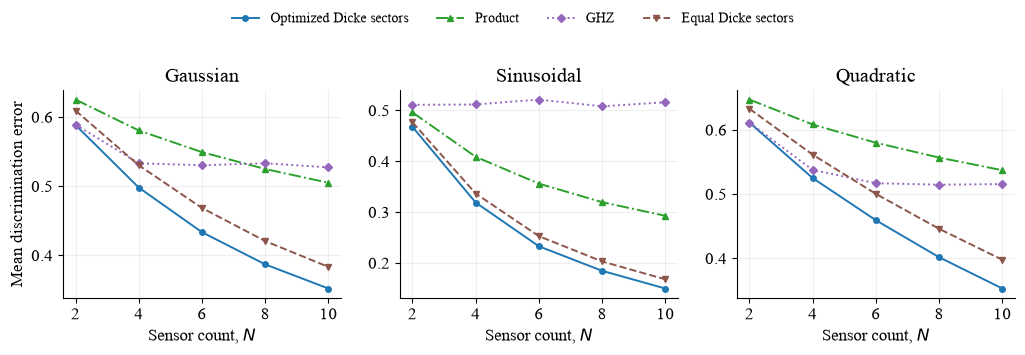

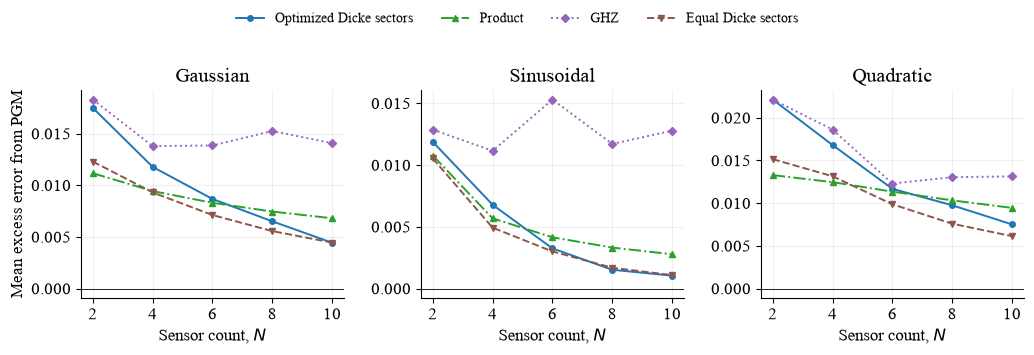

In [8]:
import importlib
import single_location.reporting as reporting

reporting = importlib.reload(reporting)
results = reporting.make_results(measurements, ROOT)
for name in ("errors", "degradation", "runtime", "validation", "optimization_audit"):
    print(name.replace("_", " ").title())
    display(results[name])


Figure 1 compares four input states using the optimal POVM for each state. Figure 2 shows the mean excess error from PGM relative to the optimal POVM on identical states. Figures are saved as PDF and 600-dpi PNG; tables are saved as CSV in `results/`.